<a href="https://colab.research.google.com/github/MarjorieMonson/Backend/blob/main/Equipo4DetAnomalias.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import IsolationForest
from sklearn.base import clone

from sklearn.metrics import (
    confusion_matrix, classification_report,
    precision_score, recall_score, f1_score,
    average_precision_score, precision_recall_curve
)

SEED = 42
pd.set_option("display.max_columns", 100)

In [3]:
import sys, sklearn, matplotlib
print("Python      :", sys.version.split()[0])
for lib in (np, pd, sklearn, matplotlib, sns):
    print(f"{lib.__name__:<12}:", lib.__version__)

Python      : 3.13.16
numpy       : 2.1.3
pandas      : 2.2.3
sklearn     : 1.6.1
matplotlib  : 3.10.0
seaborn     : 0.13.2


In [4]:
from google.colab import files
uploaded = files.upload()

Saving UNSW_NB15_testing-set.csv to UNSW_NB15_testing-set (1).csv
Saving UNSW_NB15_training-set.csv to UNSW_NB15_training-set (1).csv


In [5]:
train_path = "/content/UNSW_NB15_training-set.csv"
test_path  = "/content/UNSW_NB15_testing-set.csv"

train_raw = pd.read_csv(train_path)
test_raw  = pd.read_csv(test_path)

print("Entrenamiento:", train_raw.shape)
print("Prueba:", test_raw.shape)
display(train_raw.head())

Entrenamiento: (175341, 45)
Prueba: (82332, 45)


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,252,254,14158.942380,8495.365234,0,0,24.295600,8.375000,30.177547,11.830604,255,621772692,2202533631,255,0.000000,0.000000,0.000000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,62,252,8395.112305,503571.312500,2,17,49.915000,15.432865,61.426934,1387.778330,255,1417884146,3077387971,255,0.000000,0.000000,0.000000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,62,252,1572.271851,60929.230470,1,6,231.875571,102.737203,17179.586860,11420.926230,255,2116150707,2963114973,255,0.111897,0.061458,0.050439,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,62,252,2740.178955,3358.622070,1,3,152.876547,90.235726,259.080172,4991.784669,255,1107119177,1047442890,255,0.000000,0.000000,0.000000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,254,252,8561.499023,3987.059814,2,1,47.750333,75.659602,2415.837634,115.807000,255,2436137549,1977154190,255,0.128381,0.071147,0.057234,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0


In [6]:
print(train_raw.dtypes)
print(train_raw["label"].value_counts(dropna=False))
print(test_raw["label"].value_counts(dropna=False))
print(test_raw["label"].value_counts(normalize=True).round(3))

if "attack_cat" in test_raw.columns:
    display(test_raw["attack_cat"].fillna("Normal").value_counts())

id                     int64
dur                  float64
proto                 object
service               object
state                 object
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             int64
ct_state_ttl           int64
ct_dst_ltm             int64
ct_src_dport_l

,count
attack_cat,
Normal,37000
Generic,18871
Exploits,11132
Fuzzers,6062
DoS,4089
Reconnaissance,3496
Analysis,677
Backdoor,583
Shellcode,378


In [7]:
exclude = ["id", "label", "attack_cat"]
features = [c for c in train_raw.columns if c not in exclude]

X_train_all = train_raw[features].copy()
X_test = test_raw[features].copy()
y_test = test_raw["label"].astype(int).copy()

numeric_features = X_train_all.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in features if c not in numeric_features]

print("Número de variables de entrada:", len(features))
print("Numéricas:", numeric_features)
print("Categóricas:", categorical_features)

Número de variables de entrada: 42
Numéricas: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']
Categóricas: ['proto', 'service', 'state']


In [8]:
X_train_normal = X_train_all.loc[train_raw["label"].eq(0)].copy()

# MAX_NORMAL_TRAIN = 50_000
# if len(X_train_normal) > MAX_NORMAL_TRAIN:
#     X_train_normal = X_train_normal.sample(MAX_NORMAL_TRAIN, random_state=SEED)

print("Flujos normales para entrenamiento:", X_train_normal.shape)

Flujos normales para entrenamiento: (56000, 42)


In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ],
    remainder="drop"
)

In [10]:
model_10 = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        ("detector", IsolationForest(
            n_estimators=200,
            contamination=0.10,
            max_samples="auto",
            random_state=SEED,
            n_jobs=-1,
        )),
    ]
)

model_10.fit(X_train_normal)

pred_iforest = model_10.predict(X_test)
y_pred_10 = (pred_iforest == -1).astype(int)

In [11]:
anomaly_score_10 = -model_10.decision_function(X_test)

In [12]:
cm = confusion_matrix(y_test, y_pred_10)
print("Matriz de confusión:\n", cm)

print("\nReporte de clasificación:\n")
print(classification_report(y_test, y_pred_10, target_names=["Normal", "Ataque"], digits=3))

precision_10 = precision_score(y_test, y_pred_10, zero_division=0)
recall_10    = recall_score(y_test, y_pred_10, zero_division=0)
f1_10        = f1_score(y_test, y_pred_10, zero_division=0)
prauc_10     = average_precision_score(y_test, anomaly_score_10)

print(f"Precision: {precision_10:.3f}")
print(f"Recall:    {recall_10:.3f}")
print(f"F1:        {f1_10:.3f}")
print(f"PR-AUC:    {prauc_10:.3f}")

Matriz de confusión:
 [[31516  5484]
 [22133 23199]]

Reporte de clasificación:

              precision    recall  f1-score   support

      Normal      0.587     0.852     0.695     37000
      Ataque      0.809     0.512     0.627     45332

    accuracy                          0.665     82332
   macro avg      0.698     0.682     0.661     82332
weighted avg      0.709     0.665     0.658     82332

Precision: 0.809
Recall:    0.512
F1:        0.627
PR-AUC:    0.821


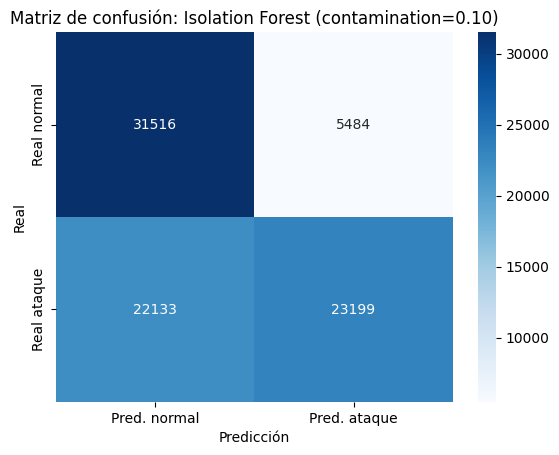

In [13]:
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred. normal", "Pred. ataque"],
            yticklabels=["Real normal", "Real ataque"])
plt.title("Matriz de confusión: Isolation Forest (contamination=0.10)")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()

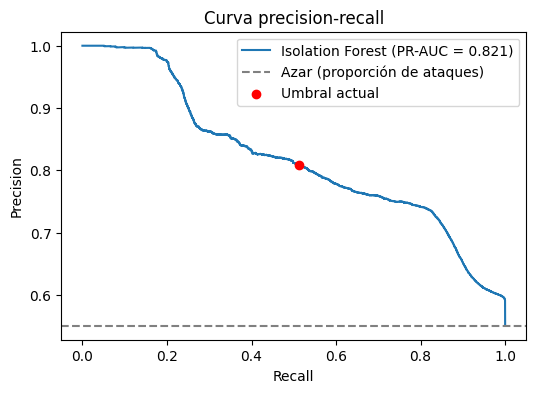

In [14]:
prec, rec, thr = precision_recall_curve(y_test, anomaly_score_10)

plt.figure(figsize=(6, 4))
plt.plot(rec, prec, label=f"Isolation Forest (PR-AUC = {prauc_10:.3f})")
plt.axhline(y_test.mean(), linestyle="--", color="gray",
            label="Azar (proporción de ataques)")
plt.scatter(recall_10, precision_10, color="red", zorder=3, label="Umbral actual")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curva precision-recall")
plt.legend()
plt.show()

In [15]:
alerts = test_raw.copy()
alerts["anomaly_score"] = anomaly_score_10
alerts["predicted_anomaly"] = y_pred_10

cols_to_show = [c for c in [
    "proto", "service", "state", "dur", "spkts", "dpkts",
    "sbytes", "dbytes", "rate", "sttl", "attack_cat", "label",
    "anomaly_score", "predicted_anomaly"
] if c in alerts.columns]

display(alerts.sort_values("anomaly_score", ascending=False)[cols_to_show].head(20))

,proto,service,state,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,attack_cat,label,anomaly_score,predicted_anomaly
19560,udp,dns,INT,0.000001,2,0,114,0,1000000.003,254,Generic,1,0.173631,1
19522,udp,dns,INT,0.000001,2,0,114,0,1000000.003,254,Generic,1,0.173631,1
19551,udp,dns,INT,0.000001,2,0,114,0,1000000.003,254,Generic,1,0.173631,1
19555,udp,dns,INT,0.000001,2,0,114,0,1000000.003,254,Generic,1,0.173631,1
19564,udp,dns,INT,0.000001,2,0,114,0,1000000.003,254,Generic,1,0.173631,1
18927,udp,dns,INT,0.000001,2,0,114,0,1000000.003,254,Generic,1,0.173631,1
17583,udp,dns,INT,0.000001,2,0,114,0,1000000.003,254,Generic,1,0.173631,1
17596,udp,dns,INT,0.000001,2,0,114,0,1000000.003,254,Generic,1,0.173631,1
17589,udp,dns,INT,0.000001,2,0,114,0,1000000.003,254,Generic,1,0.173631,1
18821,udp,dns,INT,0.000001,2,0,114,0,1000000.003,254,Generic,1,0.173631,1


In [16]:
fp = alerts[(alerts["label"] == 0) & (alerts["predicted_anomaly"] == 1)]
print("Falsos positivos:", len(fp))
display(fp.sort_values("anomaly_score", ascending=False)[cols_to_show].head(5))

fn = alerts[(alerts["label"] == 1) & (alerts["predicted_anomaly"] == 0)]
print("Falsos negativos:", len(fn))
display(fn.sort_values("anomaly_score", ascending=True)[cols_to_show].head(5))

display(fn["attack_cat"].value_counts())

Falsos positivos: 5484


,proto,service,state,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,attack_cat,label,anomaly_score,predicted_anomaly
41379,tcp,-,CON,50.755516,12,4,1996,172,0.295534,62,Normal,0,0.139873,1
41381,tcp,-,CON,50.755516,12,4,1996,172,0.295534,62,Normal,0,0.139873,1
40632,tcp,-,CON,1.089995,6,2,998,86,6.422048,62,Normal,0,0.134355,1
40633,tcp,-,CON,1.089995,6,2,998,86,6.422048,62,Normal,0,0.134355,1
41345,tcp,-,CON,48.075809,12,4,1996,172,0.312007,62,Normal,0,0.131315,1


Falsos negativos: 22133


,proto,service,state,dur,spkts,dpkts,sbytes,dbytes,rate,sttl,attack_cat,label,anomaly_score,predicted_anomaly
47142,tcp,-,FIN,0.453917,10,6,912,268,33.045689,254,Exploits,1,-0.102889,0
9776,tcp,-,FIN,0.510877,10,8,804,354,33.276111,254,Shellcode,1,-0.102662,0
50845,tcp,-,FIN,0.571043,10,6,588,268,26.267723,254,Fuzzers,1,-0.102000,0
62795,tcp,-,FIN,0.408743,10,6,590,268,36.697877,254,Fuzzers,1,-0.101640,0
50652,tcp,-,FIN,0.519796,10,8,672,354,32.705137,254,Fuzzers,1,-0.101639,0


,count
attack_cat,
Exploits,8666
Fuzzers,4672
Reconnaissance,3359
DoS,3291
Generic,910
Analysis,466
Backdoor,369
Shellcode,365
Worms,35


In [17]:
display(alerts[alerts["label"] == 0][["dur", "dpkts", "rate", "sttl"]].median())
display(alerts[alerts["label"] == 0]["state"].value_counts().head())

,0
dur,0.222840
dpkts,8.000000
rate,118.625534
sttl,62.000000


,count
state,
FIN,24172
CON,6633
INT,4485
REQ,1707
ACC,2


In [18]:
CONTAMINATION_2 = 0.05  # prueba 0.03, 0.05 o 0.20

model_2 = Pipeline(
    steps=[
        ("preprocess", clone(preprocessor)),
        ("detector", IsolationForest(
            n_estimators=200,
            contamination=CONTAMINATION_2,
            max_samples="auto",
            random_state=SEED,
            n_jobs=-1,
        )),
    ]
)

model_2.fit(X_train_normal)
y_pred_2 = (model_2.predict(X_test) == -1).astype(int)
anomaly_score_2 = -model_2.decision_function(X_test)

print("Contamination:", CONTAMINATION_2)
print("Precision:", round(precision_score(y_test, y_pred_2, zero_division=0), 3))
print("Recall:   ", round(recall_score(y_test, y_pred_2, zero_division=0), 3))
print("F1:       ", round(f1_score(y_test, y_pred_2, zero_division=0), 3))
print("PR-AUC:   ", round(average_precision_score(y_test, anomaly_score_2), 3))

Contamination: 0.05
Precision: 0.862
Recall:    0.302
F1:        0.447
PR-AUC:    0.821


In [19]:
def evaluar(nombre, y_true, y_pred, score):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "Experimento": nombre,
        "Alertas": int(y_pred.sum()),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "PR-AUC": average_precision_score(y_true, score),
    }

resultados = pd.DataFrame([
    evaluar("contamination=0.10", y_test, y_pred_10, anomaly_score_10),
    evaluar(f"contamination={CONTAMINATION_2}", y_test, y_pred_2, anomaly_score_2),
])
display(resultados.round(3))

,Experimento,Alertas,TP,FP,FN,TN,Precision,Recall,F1,PR-AUC
0,contamination=0.10,28683,23199,5484,22133,31516,0.809,0.512,0.627,0.821
1,contamination=0.05,15860,13671,2189,31661,34811,0.862,0.302,0.447,0.821
